# Problem 3: Random Kitchen Sinks vs. a one-hidden-layer MLP

Toy 2-D regression data: inputs $(x_1, x_2) \in [-3, 3]^2$, response $y$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from dataloader import HW2Dataset   # provided starter code (code/dataloader.py)

SEED = 0
ds = HW2Dataset.from_csv("../data/train (3).csv", "../data/val.csv", "../data/test.csv")
X_tr, y_tr = ds.train.X, ds.train.y
X_va, y_va = ds.val.X, ds.val.y
X_te = ds.test.X
print(f"train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape} (no labels)")
pd.DataFrame(np.c_[X_tr, y_tr], columns=["x1", "x2", "y"]).describe().round(3)

train (600, 2), validation (200, 2), test (200, 2) (no labels)


,x1,x2,y
count,600.000,600.000,600.000
mean,-0.087,-0.027,1.533
std,1.715,1.765,1.571
min,-3.000,-2.999,-1.295
25%,-1.522,-1.577,0.344
50%,-0.177,-0.074,1.284
75%,1.261,1.520,2.704
max,2.994,2.991,5.643


## Problem 3(a): visualizing the training data

Each training point is drawn at its $(x_1, x_2)$ location and colored by $y$ (single-hue sequential scale:
light = low, dark = high).

In [2]:
# Chart styling: light surface, recessive axes/grid, one-hue sequential ramp (blue, light -> dark)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE_RAMP = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
             "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_cmap = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

def style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

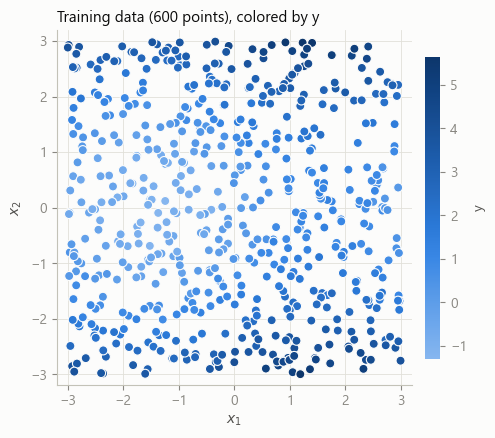

In [3]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sc = ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap=seq_cmap, s=42,
                edgecolors=SURFACE, linewidths=0.8)   # surface ring separates overlapping points
style_axes(ax)
ax.set_title("Training data (600 points), colored by y", loc="left", fontsize=11)
cb = fig.colorbar(sc, ax=ax, shrink=0.85, pad=0.03)
cb.set_label("y", color=INK2); cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED)
fig.tight_layout()
fig.savefig("../figures/p3a_train_data.png", dpi=300)
plt.show()

**Checking the structure seen in the plot.** Mean of $y$ over a coarse grid, the trend along $x_1$ after removing the bowl in $x_2$, and two least-squares fits:

In [4]:
d = pd.DataFrame(np.c_[X_tr, y_tr], columns=["x1", "x2", "y"])
grid = d.assign(x1_bin=pd.cut(d.x1, [-3.01, -1, 1, 3.01]),
                x2_bin=pd.cut(d.x2, [-3.01, -1.5, -0.5, 0.5, 1.5, 3.01]))
display(grid.pivot_table(index="x2_bin", columns="x1_bin", values="y", aggfunc="mean", observed=True).round(2))

# After removing the bowl in x2, how does y vary along x1? (finer bins)
resid = d.y - 0.5 * d.x2 ** 2
display(resid.groupby(pd.cut(d.x1, np.linspace(-3, 3, 13)), observed=True).mean().round(2)
        .rename("mean of y - 0.5 x2^2"))

def ls_fit(cols, names):
    A = np.column_stack([np.ones(len(d))] + [np.asarray(c, dtype=float) for c in cols])
    coef, *_ = np.linalg.lstsq(A, d.y, rcond=None)
    resid_var = float(np.var(d.y - A @ coef))
    return pd.Series(list(np.round(coef, 3)) + [round(1 - resid_var / np.var(d.y), 4), round(resid_var, 4)],
                     index=["1"] + names + ["R^2", "residual var"])

display(pd.DataFrame({
    "quadratic": ls_fit([d.x1, d.x2, d.x1**2, d.x2**2, d.x1 * d.x2], ["x1", "x2", "x1^2", "x2^2", "x1*x2"]),
    "x2^2 + sin(x1)": ls_fit([d.x2**2, np.sin(d.x1)], ["x2^2", "sin(x1)"]),
}))

x1_bin,"(-3.01, -1.0]","(-1.0, 1.0]","(1.0, 3.01]"
x2_bin,,,
"(-3.01, -1.5]",1.97,2.68,3.21
"(-1.5, -0.5]",-0.23,0.55,1.26
"(-0.5, 0.5]",-0.77,-0.13,0.88
"(0.5, 1.5]",-0.23,0.48,1.33
"(1.5, 3.01]",2.17,2.56,3.51


x1
(-3.0, -2.5]   -0.39
(-2.5, -2.0]   -0.74
(-2.0, -1.5]   -0.97
(-1.5, -1.0]   -0.95
(-1.0, -0.5]   -0.67
(-0.5, 0.0]    -0.28
(0.0, 0.5]      0.25
(0.5, 1.0]      0.68
(1.0, 1.5]      0.93
(1.5, 2.0]      0.99
(2.0, 2.5]      0.80
(2.5, 3.0]      0.40
Name: mean of y - 0.5 x2^2, dtype: float64

,quadratic,x2^2 + sin(x1)
1,-0.0500,-0.0080
R^2,0.9178,0.9861
residual var,0.2024,0.0343
sin(x1),NaN,1.0080
x1,0.3460,NaN
x1*x2,0.0070,NaN
x1^2,0.0090,NaN
x2,0.0070,NaN
x2^2,0.5110,0.5040


## Problem 3(b): Random Kitchen Sinks with ridge regression

`RandomKitchenSinks` in `models.py`: $h = D/2$ random directions $w_j \sim N(0, I/\sigma^2)$ and phases
$b_j \sim U[0, 2\pi]$, features $[\sin(w_j^\top x + b_j), \cos(w_j^\top x + b_j)]_{j=1}^h$ plus an intercept
column, and the closed-form ridge solution $\beta = (\Phi^\top\Phi + \lambda I')^{-1}\Phi^\top y$ (intercept not penalized).

**Sweep:** the kernel scale $\sigma$, with $D = 1000$ ($h = 500$), $\lambda = 10^{-3}$ and random seed 0 held fixed.

In [5]:
from models import RandomKitchenSinks

def mse(pred, y):
    return float(np.mean((pred - y) ** 2))

D_FIXED, LAMBDA_FIXED = 1000, 1e-3
SIGMAS = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0, 10.0]

rows = []
for s in SIGMAS:
    m = RandomKitchenSinks(D=D_FIXED, sigma=s, ridge_lambda=LAMBDA_FIXED, seed=SEED).fit(X_tr, y_tr)
    rows.append({"sigma": s, "train MSE": mse(m.predict(X_tr), y_tr), "val MSE": mse(m.predict(X_va), y_va)})
rks_sweep = pd.DataFrame(rows).set_index("sigma")
best_sigma = float(rks_sweep["val MSE"].idxmin())
print(f"best sigma = {best_sigma}  (validation MSE {rks_sweep['val MSE'].min():.4f})")
rks_sweep.round(4)

best sigma = 5.0  (validation MSE 0.0362)


,train MSE,val MSE
sigma,,
0.10,0.0000,1.4668
0.20,0.0063,1.9505
0.30,0.0149,0.1064
0.50,0.0234,0.0595
0.75,0.0272,0.0494
1.00,0.0288,0.0455
1.50,0.0298,0.0403
2.00,0.0304,0.0381
3.00,0.0320,0.0369


Is the choice stable across random draws of the features? Validation MSE for 5 seeds:

In [6]:
seed_check = pd.DataFrame({
    seed: [mse(RandomKitchenSinks(D=D_FIXED, sigma=s, ridge_lambda=LAMBDA_FIXED, seed=seed)
               .fit(X_tr, y_tr).predict(X_va), y_va) for s in SIGMAS]
    for seed in range(5)}, index=pd.Index(SIGMAS, name="sigma"))
seed_check["mean"] = seed_check.mean(axis=1)
print("best sigma per seed:", seed_check.drop(columns="mean").idxmin().tolist())
seed_check.round(4)

best sigma per seed: [5.0, 5.0, 5.0, 5.0, 5.0]


,0,1,2,3,4,mean
sigma,,,,,,
0.10,1.4668,1.1626,3.9041,1.7658,1.4727,1.9544
0.20,1.9505,2.8158,1.3069,1.4914,2.8091,2.0748
0.30,0.1064,0.0931,0.1311,0.1497,0.1660,0.1293
0.50,0.0595,0.0538,0.0610,0.0652,0.0627,0.0604
0.75,0.0494,0.0491,0.0474,0.0475,0.0493,0.0486
1.00,0.0455,0.0454,0.0450,0.0450,0.0449,0.0451
1.50,0.0403,0.0400,0.0396,0.0402,0.0400,0.0400
2.00,0.0381,0.0380,0.0377,0.0381,0.0379,0.0380
3.00,0.0369,0.0377,0.0371,0.0372,0.0372,0.0372


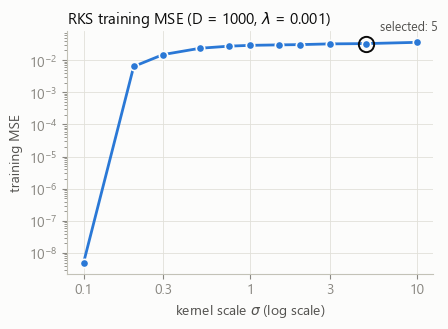

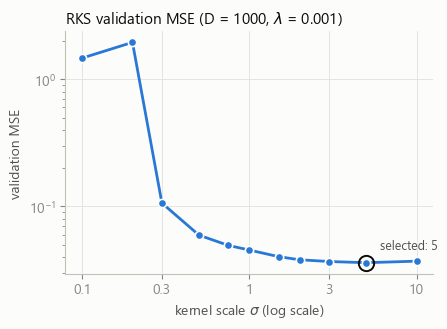

In [7]:
LINE = "#2a78d6"   # single series: categorical slot 1

def sweep_plot(x, y, xlabel, ylabel, title, best_x, filename, xticks=None):
    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    ax.plot(x, y, color=LINE, linewidth=2, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.2)
    i = list(x).index(best_x)
    ax.plot([best_x], [y[i]], marker="o", markersize=11, markerfacecolor="none",
            markeredgecolor=INK, markeredgewidth=1.4)
    ax.annotate(f"selected: {best_x:g}", (best_x, y[i]), textcoords="offset points",
                xytext=(10, 10), color=INK2, fontsize=9)
    ax.set_xscale("log")
    ticks = list(x) if xticks is None else xticks
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    if max(y) / min(y) > 20:
        ax.set_yscale("log")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11)
    fig.tight_layout()
    fig.savefig(filename, dpi=300)
    plt.show()

sx = rks_sweep.index.to_list()
sweep_plot(sx, rks_sweep["train MSE"].to_list(), r"kernel scale $\sigma$ (log scale)", "training MSE",
           f"RKS training MSE (D = {D_FIXED}, $\\lambda$ = {LAMBDA_FIXED:g})", best_sigma,
           "../figures/p3b_rks_train_mse.png", xticks=[0.1, 0.3, 1, 3, 10])
sweep_plot(sx, rks_sweep["val MSE"].to_list(), r"kernel scale $\sigma$ (log scale)", "validation MSE",
           f"RKS validation MSE (D = {D_FIXED}, $\\lambda$ = {LAMBDA_FIXED:g})", best_sigma,
           "../figures/p3b_rks_val_mse.png", xticks=[0.1, 0.3, 1, 3, 10])

## Problem 3(c): one-hidden-layer MLP

`MLP` in `models.py`: Linear($2 \to$ width) $\to$ ReLU $\to$ Linear(width $\to 1$), trained with MSE loss and Adam
(learning rate $10^{-3}$), batch size 128, 1000 epochs, seed 0.

**Sweep:** the hidden width, with everything else held fixed (`mlp_sweep` in `models.py`).

In [8]:
import time
from models import MLP, mlp_sweep

WIDTHS = [2, 4, 8, 16, 32, 64, 128, 256, 512]
t0 = time.time()
mlp_best, mlp_best_val, best_width, records = mlp_sweep(WIDTHS, X_tr, y_tr, X_va, y_va)
print(f"sweep took {time.time() - t0:.0f}s; best width = {best_width} (validation MSE {mlp_best_val:.4f})")
mlp_sweep_df = pd.DataFrame(records).set_index("d_hidden")
mlp_sweep_df.round(4)

sweep took 34s; best width = 128 (validation MSE 0.0386)


,train MSE,val MSE
d_hidden,,
2,0.2959,0.3130
4,0.3125,0.3384
8,0.0682,0.0707
16,0.0390,0.0459
32,0.0332,0.0389
64,0.0317,0.0395
128,0.0294,0.0386
256,0.0295,0.0389
512,0.0278,0.0390


Is the choice stable across random seeds (initialization and batch order)? Validation MSE for 3 seeds:

In [9]:
t0 = time.time()
mlp_seed_check = pd.DataFrame({
    seed: [float(np.mean((MLP(d_in=2, d_hidden=w, seed=seed).fit(X_tr, y_tr).predict(X_va).ravel() - y_va) ** 2))
           for w in WIDTHS]
    for seed in range(3)}, index=pd.Index(WIDTHS, name="d_hidden"))
mlp_seed_check["mean"] = mlp_seed_check.mean(axis=1)
print(f"took {time.time() - t0:.0f}s; best width per seed:",
      mlp_seed_check.drop(columns="mean").idxmin().tolist())
mlp_seed_check.round(4)

took 95s; best width per seed: [128, 32, 128]


,0,1,2,mean
d_hidden,,,,
2,0.3130,0.3224,1.4650,0.7002
4,0.3384,0.2267,0.2335,0.2662
8,0.0707,0.1774,0.1035,0.1172
16,0.0459,0.0515,0.0618,0.0531
32,0.0389,0.0392,0.0405,0.0395
64,0.0395,0.0400,0.0395,0.0397
128,0.0386,0.0400,0.0388,0.0391
256,0.0389,0.0399,0.0402,0.0397
512,0.0390,0.0394,0.0391,0.0391


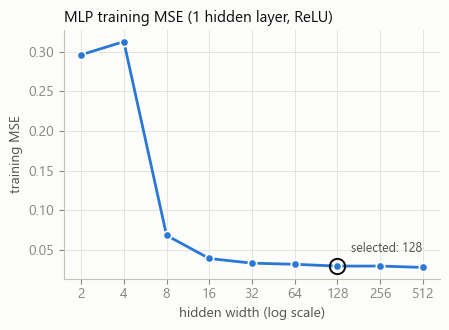

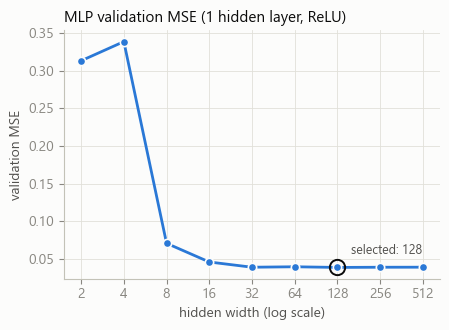

In [10]:
wx = mlp_sweep_df.index.to_list()
sweep_plot(wx, mlp_sweep_df["train MSE"].to_list(), "hidden width (log scale)", "training MSE",
           "MLP training MSE (1 hidden layer, ReLU)", best_width, "../figures/p3c_mlp_train_mse.png")
sweep_plot(wx, mlp_sweep_df["val MSE"].to_list(), "hidden width (log scale)", "validation MSE",
           "MLP validation MSE (1 hidden layer, ReLU)", best_width, "../figures/p3c_mlp_val_mse.png")

## Problem 3(d): comparison and visualization

Refit both models on the training set with the selected hyperparameters (seed 0) and report their MSE.

In [11]:
rks_final = RandomKitchenSinks(D=D_FIXED, sigma=best_sigma, ridge_lambda=LAMBDA_FIXED, seed=SEED).fit(X_tr, y_tr)
mlp_final = MLP(d_in=2, d_hidden=int(best_width), seed=SEED).fit(X_tr, y_tr)

rks_pred = lambda X: rks_final.predict(X)
mlp_pred = lambda X: mlp_final.predict(X).ravel()

final = pd.DataFrame({
    f"RKS + ridge (D={D_FIXED}, sigma={best_sigma:g}, lambda={LAMBDA_FIXED:g})":
        {"train MSE": mse(rks_pred(X_tr), y_tr), "val MSE": mse(rks_pred(X_va), y_va)},
    f"1-hidden-layer MLP (width={best_width})":
        {"train MSE": mse(mlp_pred(X_tr), y_tr), "val MSE": mse(mlp_pred(X_va), y_va)},
}).T
final.round(4)

,train MSE,val MSE
"RKS + ridge (D=1000, sigma=5, lambda=0.001)",0.0327,0.0362
1-hidden-layer MLP (width=128),0.0294,0.0386


**Test-set predictions.** `test.csv` is unlabeled; both models predict on it and the predictions are written
one per row (no header), in the same order as `test.csv`.

In [12]:
rks_test = rks_pred(X_te)
mlp_test = mlp_pred(X_te)
np.savetxt("../rks_test_predictions.csv", rks_test, fmt="%.6f")
np.savetxt("../mlp_test_predictions.csv", mlp_test, fmt="%.6f")
print(f"wrote {len(rks_test)} RKS and {len(mlp_test)} MLP predictions")
print(f"correlation between the two models' test predictions: {np.corrcoef(rks_test, mlp_test)[0, 1]:.4f}")
print(f"mean absolute difference: {np.mean(np.abs(rks_test - mlp_test)):.4f}")

wrote 200 RKS and 200 MLP predictions
correlation between the two models' test predictions: 0.9995
mean absolute difference: 0.0396


**Fitted surfaces.** Adapted from the provided `plot_surface_2d` (same 200 x 200 grid over $[-3, 3]^2$ and
filled contours), but drawn with the same color scale as the training-data plot in 3(a) so the three
figures can be compared directly.

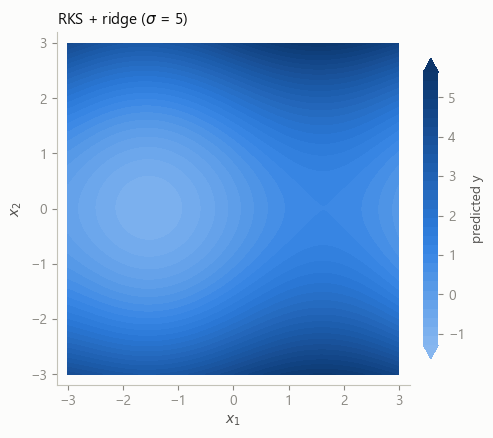

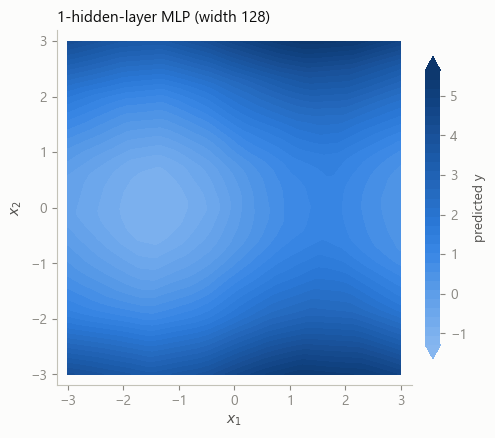

max |RKS - MLP| over the grid: 0.183; mean: 0.038


In [13]:
def surface_plot(predict_fn, title, filename, grid=200):
    xs = np.linspace(-3, 3, grid)
    X1, X2 = np.meshgrid(xs, xs)
    Z = predict_fn(np.stack([X1.ravel(), X2.ravel()], axis=1)).reshape(grid, grid)
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    cf = ax.contourf(X1, X2, Z, levels=np.linspace(y_tr.min(), y_tr.max(), 31), cmap=seq_cmap, extend="both")
    for c in cf.collections if hasattr(cf, "collections") else []:
        c.set_rasterized(True)
    ax.grid(False)
    style_axes(ax)
    ax.set_title(title, loc="left", fontsize=11)
    cb = fig.colorbar(cf, ax=ax, shrink=0.85, pad=0.03, ticks=range(-1, 6))
    cb.set_label("predicted y", color=INK2); cb.outline.set_visible(False)
    cb.ax.tick_params(colors=MUTED)
    fig.tight_layout()
    fig.savefig(filename, dpi=300)
    plt.show()
    return Z

Z_rks = surface_plot(rks_pred, f"RKS + ridge ($\\sigma$ = {best_sigma:g})", "../figures/p3d_rks_surface.png")
Z_mlp = surface_plot(mlp_pred, f"1-hidden-layer MLP (width {best_width})", "../figures/p3d_mlp_surface.png")
print(f"max |RKS - MLP| over the grid: {np.max(np.abs(Z_rks - Z_mlp)):.3f}; "
      f"mean: {np.mean(np.abs(Z_rks - Z_mlp)):.3f}")